# [9660] Principal Component Analysis 1
Data file:
* sklearn : breast_cancer

In [ ]:
from datetime import datetime
print(f'Run time: {datetime.now().strftime("%D %T")}')

Run time: 11/23/26 17:14:26


### Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn import decomposition
import warnings
warnings.simplefilter(action='ignore', category=UserWarning)

### Load data

In [ ]:
cancer = load_breast_cancer()

In [ ]:
df = pd.DataFrame(data=cancer['data'], columns=cancer['feature_names'])
df['target'] = cancer['target']
df.shape

(569, 31)

## 30 features, 1 Y (TARGET (we have a breast cancer or not)

In [ ]:
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [ ]:
print(cancer.DESCR)

.. _breast_cancer_dataset:

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [ ]:
pd.set_option('display.max_columns', None)
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


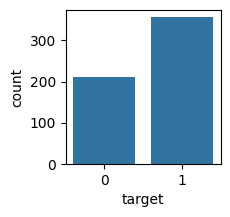

In [ ]:
# Plot outcome counts
plt.figure(figsize=(2,2))
sns.countplot(data=df, x='target')
plt.show()

To understand how the features affect the target, let's plot histograms of malignant and benign classes.  
If the two histograms are clearly separated based on the feature, that feature is important for classifying instances.

### 30 features on Y

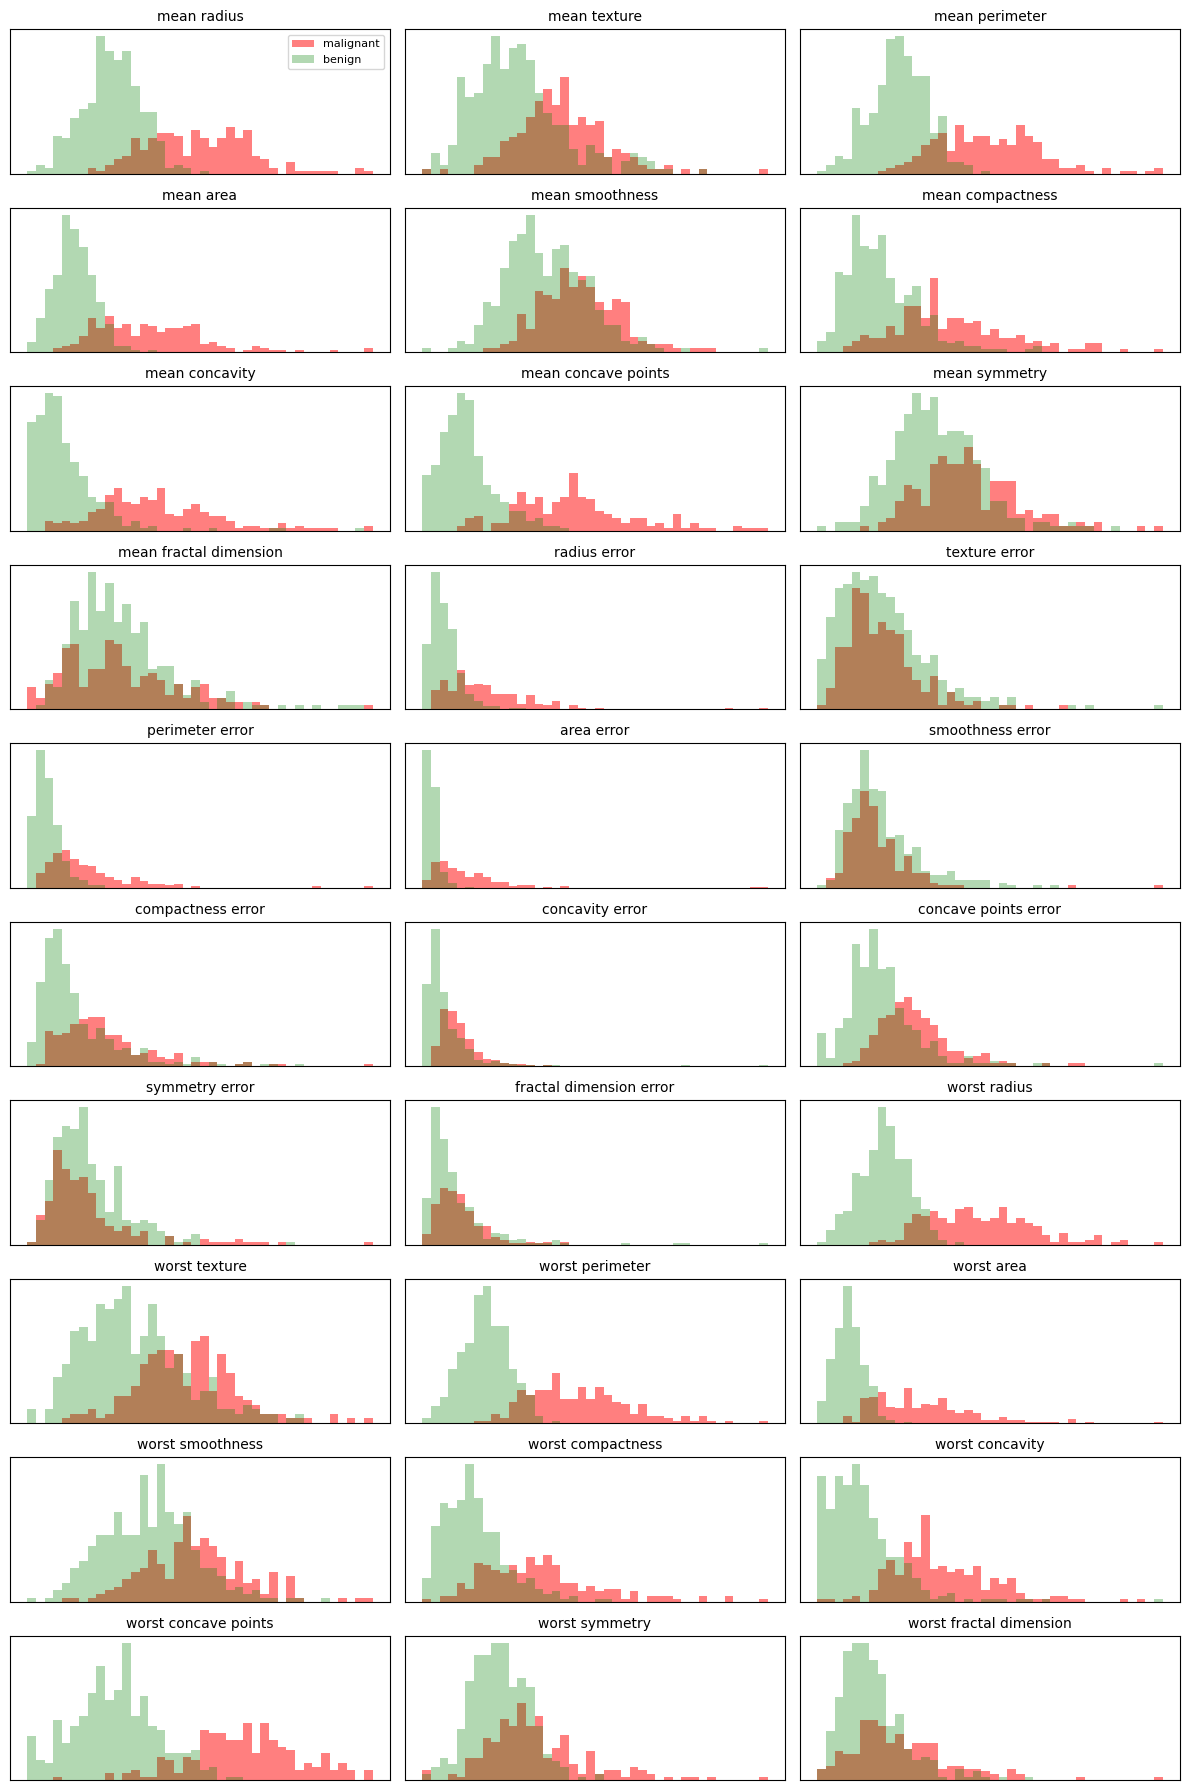

In [ ]:
# Define 3 columns, each containing 10 figures, totaling 30 figures
fig, axes = plt.subplots(10, 3, figsize=(12, 18))

# Define malignant and benign
malignant = cancer.data[cancer.target==0]
benign = cancer.data[cancer.target==1]

# flat axes with numpy ravel
ax=axes.ravel()
for i in range(30):
    _,bins=np.histogram(cancer.data[:,i],bins=40)
    # red color is for malignant class
    # alpha is for transparency in the overlapped region
    ax[i].hist(malignant[:,i],bins=bins, color='r', alpha=.5)
    # green color is for benign class
    ax[i].hist(benign[:,i],bins=bins, color='g', alpha=0.3)
    ax[i].set_title(cancer.feature_names[i], fontsize=10)
    # the x-axis co-ordinates are not so useful, as we just want to look how well
    #  separated the histograms are
    ax[i].axes.get_xaxis().set_visible(False)
    ax[i].set_yticks(())
ax[0].legend(['malignant','benign'], loc='best', fontsize=8)

# Define layout for plots
plt.tight_layout()
plt.show()

From these histograms, we see that features like "mean fractal dimension" DO NOT discriminate malignant from benign, but "worst concave points" or "worst perimeter" DO and therefore are useful features.

Given the number of features in this dataset, there is a high probability that some of the features are correlated.  
First, let's review a correlation matrix of the dataset.

<Axes: >

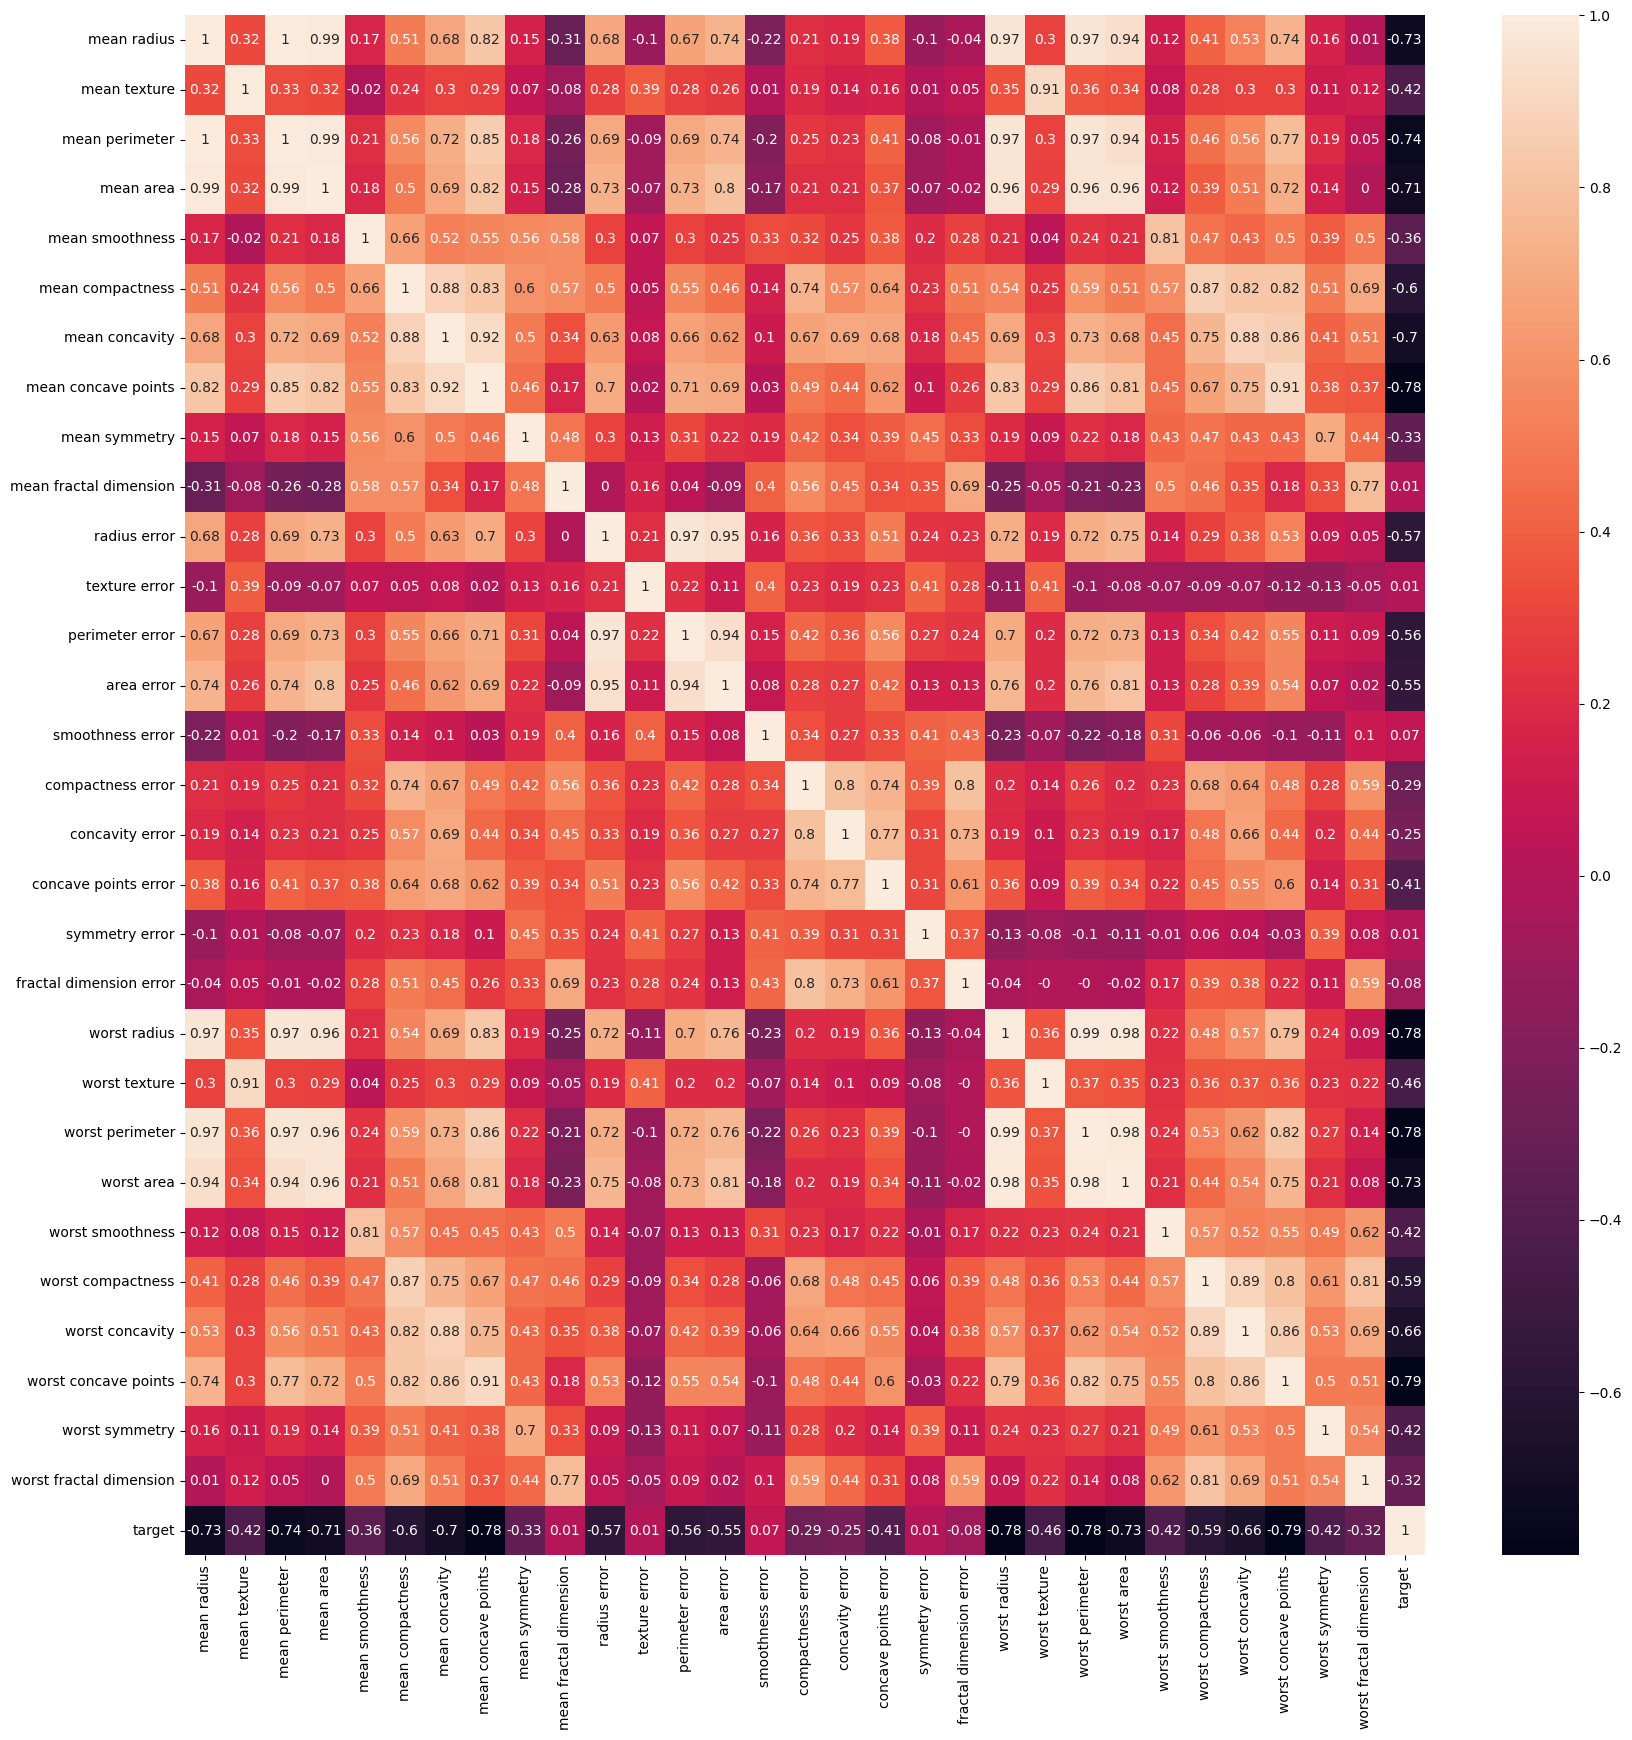

In [ ]:
plt.figure(figsize=(20,20))
# Calculate the linear relationships between the variables
correlation_matrix = df.corr().round(2)
sns.heatmap(correlation_matrix, annot=True)

Since the correlation matrix is very dense, let's examine a few pairs of features.

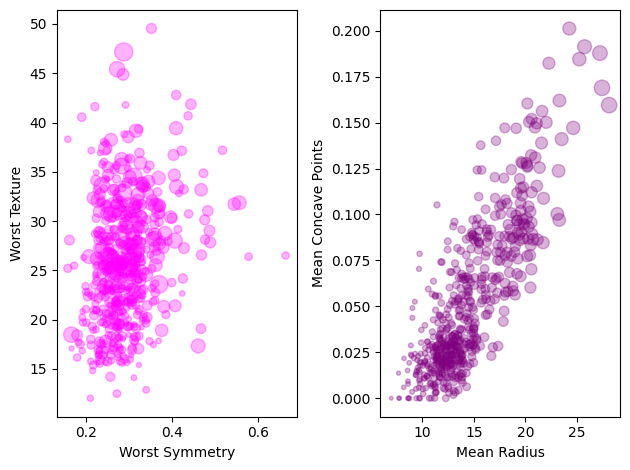

In [ ]:
# Setup first plot
plt.subplot(1,2,1)
plt.scatter(df['worst symmetry'], df['worst texture'],
            s = df['worst area']*0.05,
            color='magenta', label='check', alpha=0.3)
plt.xlabel('Worst Symmetry',fontsize=10)
plt.ylabel('Worst Texture',fontsize=10)

# Setup second plot
plt.subplot(1,2,2)
plt.scatter(df['mean radius'], df['mean concave points'],
            s = df['mean area']*0.05,
            color='purple', label='check', alpha=0.3)
plt.xlabel('Mean Radius', fontsize=10)
plt.ylabel('Mean Concave Points', fontsize=10)
plt.tight_layout()
plt.show()

The feature pair in the righthand plot appear to be more closely correlated than the feature pair in the lefthand plot.

### Prepare data for PCA

In [ ]:
# Instantiate StandardScalar
scaler=StandardScaler()

In [ ]:
# Check min and max before scaling
print("Before scaling minimum:\n", cancer.data.min(axis=0))
print()
print("Before scaling maximum:\n", cancer.data.max(axis=0))

# Compute the mean and variance of each feature
scaler.fit(cancer.data)

# Transform each feature using its respective mean and variance (computed above)
X_scaled=scaler.transform(cancer.data)

# Check min and max after scaling
print("\nAfter scaling minimum:\n", X_scaled.min(axis=0))
print()
print("After scaling maximum:\n", X_scaled.max(axis=0))

Before scaling minimum:
 [6.981e+00 9.710e+00 4.379e+01 1.435e+02 5.263e-02 1.938e-02 0.000e+00
 0.000e+00 1.060e-01 4.996e-02 1.115e-01 3.602e-01 7.570e-01 6.802e+00
 1.713e-03 2.252e-03 0.000e+00 0.000e+00 7.882e-03 8.948e-04 7.930e+00
 1.202e+01 5.041e+01 1.852e+02 7.117e-02 2.729e-02 0.000e+00 0.000e+00
 1.565e-01 5.504e-02]

Before scaling maximum:
 [2.811e+01 3.928e+01 1.885e+02 2.501e+03 1.634e-01 3.454e-01 4.268e-01
 2.012e-01 3.040e-01 9.744e-02 2.873e+00 4.885e+00 2.198e+01 5.422e+02
 3.113e-02 1.354e-01 3.960e-01 5.279e-02 7.895e-02 2.984e-02 3.604e+01
 4.954e+01 2.512e+02 4.254e+03 2.226e-01 1.058e+00 1.252e+00 2.910e-01
 6.638e-01 2.075e-01]

After scaling minimum:
 [-2.0296483  -2.22924851 -1.98450403 -1.45444309 -3.11208479 -1.61013634
 -1.11487284 -1.26181958 -2.74411707 -1.81986478 -1.05992413 -1.55426392
 -1.04404888 -0.73782907 -1.77606498 -1.2980982  -1.05750068 -1.91344745
 -1.53289003 -1.09696818 -1.72690052 -2.22399401 -1.69336103 -1.22242284
 -2.68269492 -1.4438

### Perform Principal Component Analysis (PCA)

In [ ]:
X_scaled

array([[ 1.09706398, -2.07333501,  1.26993369, ...,  2.29607613,
         2.75062224,  1.93701461],
       [ 1.82982061, -0.35363241,  1.68595471, ...,  1.0870843 ,
        -0.24388967,  0.28118999],
       [ 1.57988811,  0.45618695,  1.56650313, ...,  1.95500035,
         1.152255  ,  0.20139121],
       ...,
       [ 0.70228425,  2.0455738 ,  0.67267578, ...,  0.41406869,
        -1.10454895, -0.31840916],
       [ 1.83834103,  2.33645719,  1.98252415, ...,  2.28998549,
         1.91908301,  2.21963528],
       [-1.80840125,  1.22179204, -1.81438851, ..., -1.74506282,
        -0.04813821, -0.75120669]], shape=(569, 30))

In [ ]:
pca = decomposition.PCA(n_components=3, random_state=42)
pca.fit(X_scaled)
X_pca = pca.transform(X_scaled)

X_pca.shape

(569, 3)

In [ ]:
## zi1, zi2, zi3

In [ ]:
X_pca

array([[ 9.19283683,  1.94858307, -1.12316616],
       [ 2.3878018 , -3.76817174, -0.52929269],
       [ 5.73389628, -1.0751738 , -0.55174759],
       ...,
       [ 1.25617928, -1.90229671,  0.56273053],
       [10.37479406,  1.67201011, -1.87702933],
       [-5.4752433 , -0.67063679,  1.49044308]], shape=(569, 3))

In [ ]:
X_pca.shape

(569, 3)

#### Calculate variance ratios for each principal component

In [ ]:
ex_variance = np.var(X_pca, axis=0)
ex_variance_ratio = ex_variance/np.sum(ex_variance)
print(f"1st component ratio = {round(ex_variance_ratio[0],4)}")
print(f"2nd component ratio = {round(ex_variance_ratio[1],4)}")
print(f"3rd component ratio = {round(ex_variance_ratio[2],4)}")

1st component ratio = 0.6095
2nd component ratio = 0.2612
3rd component ratio = 0.1293


We can see that the first 2 principal components contributes to 87% of the total variance.

Next, let's plot the first 2 principal components against their target classes.

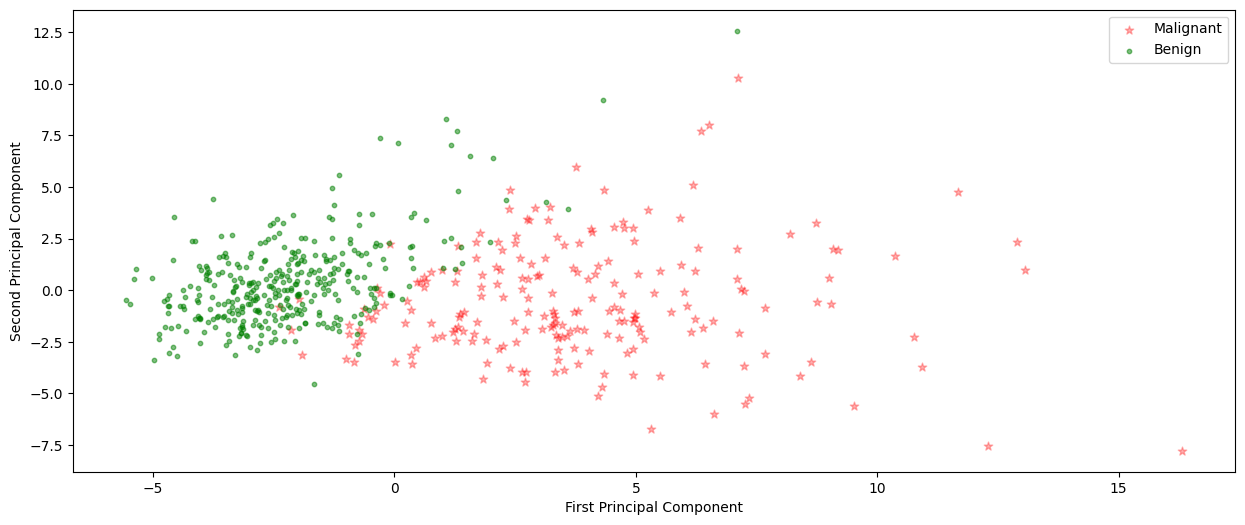

In [ ]:
Xax = X_pca[:,0]
Yax = X_pca[:,1]
labels = cancer.target
cdict = {0:'red',1:'green'}
labl = {0:'Malignant',1:'Benign'}
marker = {0:'*',1:'.'}
alpha = {0:.3, 1:.5}
fig,ax = plt.subplots(figsize=(15,6))
fig.patch.set_facecolor('white')
for l in np.unique(labels):
    ix=np.where(labels==l)
    ax.scatter(Xax[ix], Yax[ix], c=cdict[l], s=40,
               label=labl[l], marker=marker[l], alpha=alpha[l])

plt.xlabel("First Principal Component", fontsize=10)
plt.ylabel("Second Principal Component", fontsize=10)
plt.legend()
plt.show()

As we can clearly see, using the first 2 principal components as our features, the two classes are well separated

#### Review each original feature's contribution to each principal component

* The weights for 30 features

In [ ]:
# Q1=(Q11, Q21,Q31,...Q30_1)

In [ ]:
# Q2=(Q12, Q22, Q32,...Q30_2)

In [ ]:
# Q3= (Q13, Q23, Q33,..., Q30_3)

In [ ]:
# Zi1=Q11Xi1+Q21Xi2+...+Q30_1*Xi30

In [ ]:
# Zi2=Q12Xi1+Q22Xi2+...+Q30_2*Xi30

In [ ]:
# Zi3=Q13Xi1+Q23Xi2+....+Q30_3*Xi30

In [ ]:
pca.components_.shape

(3, 30)

In [ ]:
pca.components_  # weights

array([[ 0.21890244,  0.10372458,  0.22753729,  0.22099499,  0.14258969,
         0.23928535,  0.25840048,  0.26085376,  0.13816696,  0.06436335,
         0.20597878,  0.01742803,  0.21132592,  0.20286964,  0.01453145,
         0.17039345,  0.15358979,  0.1834174 ,  0.04249842,  0.10256832,
         0.22799663,  0.10446933,  0.23663968,  0.22487053,  0.12795256,
         0.21009588,  0.22876753,  0.25088597,  0.12290456,  0.13178394],
       [-0.23385713, -0.05970609, -0.21518136, -0.23107671,  0.18611302,
         0.15189161,  0.06016536, -0.0347675 ,  0.19034877,  0.36657547,
        -0.10555215,  0.08997968, -0.08945723, -0.15229263,  0.20443045,
         0.2327159 ,  0.19720728,  0.13032156,  0.183848  ,  0.28009203,
        -0.21986638, -0.0454673 , -0.19987843, -0.21935186,  0.17230435,
         0.14359317,  0.09796411, -0.00825724,  0.14188335,  0.27533947],
       [-0.00853124,  0.0645499 , -0.00931422,  0.02869953, -0.1042919 ,
        -0.07409157,  0.00273384, -0.02556354, -0

In [ ]:
X_scaled # oringinal scaled dataset

array([[ 1.09706398, -2.07333501,  1.26993369, ...,  2.29607613,
         2.75062224,  1.93701461],
       [ 1.82982061, -0.35363241,  1.68595471, ...,  1.0870843 ,
        -0.24388967,  0.28118999],
       [ 1.57988811,  0.45618695,  1.56650313, ...,  1.95500035,
         1.152255  ,  0.20139121],
       ...,
       [ 0.70228425,  2.0455738 ,  0.67267578, ...,  0.41406869,
        -1.10454895, -0.31840916],
       [ 1.83834103,  2.33645719,  1.98252415, ...,  2.28998549,
         1.91908301,  2.21963528],
       [-1.80840125,  1.22179204, -1.81438851, ..., -1.74506282,
        -0.04813821, -0.75120669]], shape=(569, 30))

In [ ]:
X_scaled.shape

(569, 30)

In [ ]:
# (569,30) * (30,3)= (569,3)

In [ ]:
weights_tranpose=pca.components_.transpose()

In [ ]:
weights_m=np.asmatrix(weights_tranpose)

In [ ]:
weights_m

matrix([[ 0.21890244, -0.23385713, -0.00853124],
        [ 0.10372458, -0.05970609,  0.0645499 ],
        [ 0.22753729, -0.21518136, -0.00931422],
        [ 0.22099499, -0.23107671,  0.02869953],
        [ 0.14258969,  0.18611302, -0.1042919 ],
        [ 0.23928535,  0.15189161, -0.07409157],
        [ 0.25840048,  0.06016536,  0.00273384],
        [ 0.26085376, -0.0347675 , -0.02556354],
        [ 0.13816696,  0.19034877, -0.04023994],
        [ 0.06436335,  0.36657547, -0.02257409],
        [ 0.20597878, -0.10555215,  0.26848139],
        [ 0.01742803,  0.08997968,  0.37463367],
        [ 0.21132592, -0.08945723,  0.26664537],
        [ 0.20286964, -0.15229263,  0.21600653],
        [ 0.01453145,  0.20443045,  0.30883898],
        [ 0.17039345,  0.2327159 ,  0.15477972],
        [ 0.15358979,  0.19720728,  0.17646374],
        [ 0.1834174 ,  0.13032156,  0.22465757],
        [ 0.04249842,  0.183848  ,  0.28858429],
        [ 0.10256832,  0.28009203,  0.21150376],
        [ 0.22799663

In [ ]:
X_scaled_matrix=np.asmatrix(X_scaled)

In [ ]:
X_scaled_matrix * weights_m

matrix([[ 9.19283683,  1.94858307, -1.12316616],
        [ 2.3878018 , -3.76817174, -0.52929269],
        [ 5.73389628, -1.0751738 , -0.55174759],
        ...,
        [ 1.25617928, -1.90229671,  0.56273053],
        [10.37479406,  1.67201011, -1.87702933],
        [-5.4752433 , -0.67063679,  1.49044308]], shape=(569, 3))

In [ ]:
X_pca# principle components scores

array([[ 9.19283683,  1.94858307, -1.12316616],
       [ 2.3878018 , -3.76817174, -0.52929269],
       [ 5.73389628, -1.0751738 , -0.55174759],
       ...,
       [ 1.25617928, -1.90229671,  0.56273053],
       [10.37479406,  1.67201011, -1.87702933],
       [-5.4752433 , -0.67063679,  1.49044308]], shape=(569, 3))

In [ ]:
X_pca.shape

(569, 3)

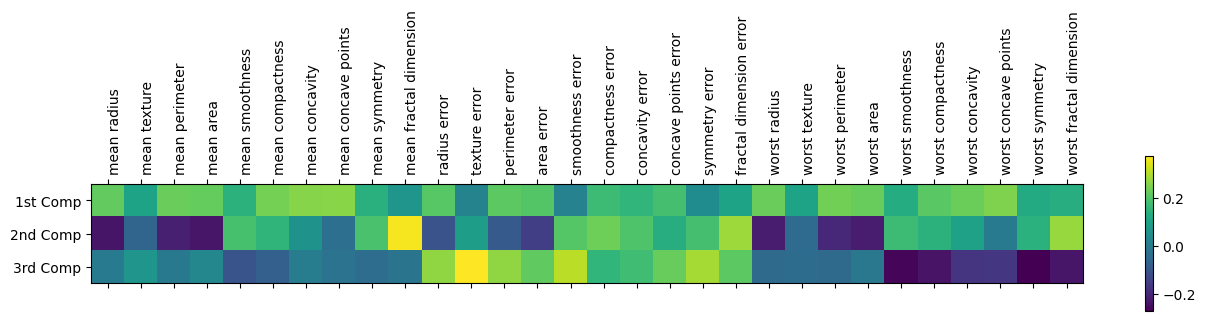

In [ ]:
plt.matshow(pca.components_, cmap='viridis')
plt.yticks([0,1,2], ['1st Comp','2nd Comp','3rd Comp'], fontsize=10)
plt.colorbar()
plt.xticks(range(len(cancer.feature_names)), cancer.feature_names,
           rotation=90, ha='left')
plt.tight_layout()
plt.show()